In [20]:
# 그래프 관련
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np

# 머신러닝 관련
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier  #평균절대값오차
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

In [21]:
# 길이, 무게, 두께

perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]
    )

In [22]:
train_data,test_data,train_label,test_label = \
    train_test_split(perch_length,perch_weight)
train_data = train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)

In [23]:
#선형 회귀
lr = LinearRegression()
lr.fit(train_data, train_label)
predict = lr.predict(test_data)
print('무게예측: ', predict)
score = lr.score(train_data, train_label)
score2 = lr.score(test_data, test_label)
print(f'정확도:{score*100}%, {score2*100}*')

무게예측:  [-106.03217436  823.99667425  786.79552031  935.60013609  358.98224995
  358.98224995   31.61209524  786.79552031  358.98224995  172.97648023
   65.09313379  -16.74940489  619.39032756 -154.39367449]
정확도:91.69616921515775%, 92.1727362661276*


In [32]:
print('기울기: ', lr.coef_)
print('y절편: ', lr.intercept_)

기울기:  [37.20115394]
y절편:  -664.0494835239937


In [ ]:
# #선형 회귀
# predict2 = lr.predict([[50]])
# print('무게예측2: ', predict2)

무게예측2:  [1196.0082137]


예측무게: [2312.04283203]


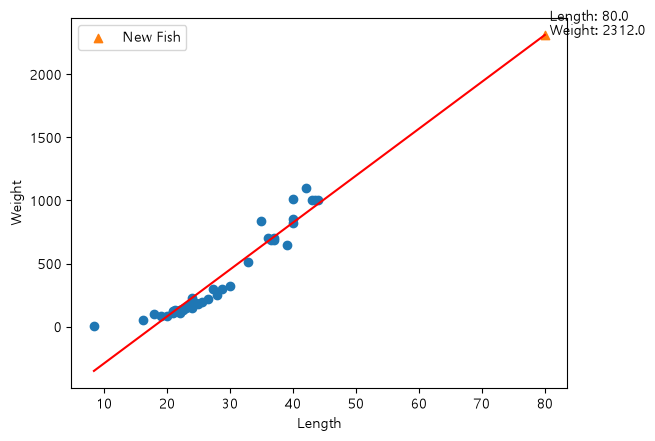

In [40]:
# 길이를 입력받아 무게 예측하기
i_data = input('생선의 길이 입력(예: 27(cm))')
i_data = float(i_data)
predict = lr.predict([[i_data]])
print('예측무게:',predict)

# 삼점도 그래프
plt.scatter(train_data,train_label)
plt.plot([8.4,i_data],[8.4 * lr.coef_ + lr.intercept_, i_data * lr.coef_ + lr.intercept_], color='red')
plt.scatter(i_data,predict, marker='^', label='New Fish')
plt.text(i_data, predict[0], f' Length: {i_data}\n Weight: {predict[0]:.1f}')
plt.xlabel('Length')
plt.ylabel('Weight')
plt.legend()
plt.show()